<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/statistics/T3_PosDL_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Banco de Dados 1: Titanic**

## **Descrição**

O **Titanic** dataset é um conjunto de dados histórico sobre o desastre do Titanic, contendo informações sobre os passageiros e a sobrevivência deles. Este dataset é amplamente utilizado em problemas de aprendizado de máquina, especialmente para classificar sobreviventes e não sobreviventes com base em várias características.

- **Fonte**: [Seaborn](https://seaborn.pydata.org/generated/seaborn.load_dataset.html#seaborn.load_dataset)  
- **Número de Registros**: 891 instâncias  
- **Número de Atributos**: 12 atributos

## **Atributos**:
1. `survived` - Indicador de sobrevivência (0 = Não sobreviveu, 1 = Sobreviveu).
2. `pclass` - Classe do passageiro (1 = 1ª classe, 2 = 2ª classe, 3 = 3ª classe).
3. `sex` - Sexo do passageiro (masculino ou feminino).
4. `age` - Idade do passageiro.
5. `sibsp` - Número de irmãos/irmãs ou cônjuges a bordo.
6. `parch` - Número de pais ou filhos a bordo.
7. `fare` - Valor da tarifa do bilhete.
8. `embarked` - Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton).
9. `class` - Classe de embarque (1ª, 2ª, 3ª classe).
10. `who` - Sexo do passageiro, categorizado como "man", "woman", ou "child".
11. `alone` - Indicador de se o passageiro estava sozinho (Yes = Sim, No = Não).
12. `deck` - Deck do navio (A, B, C, etc.), onde o passageiro foi alocado.

## **Objetivo**:
O objetivo principal desse dataset é prever se um passageiro sobreviveu ou não ao desastre do Titanic com base em suas características, como classe, idade, sexo, entre outros.


In [164]:
## Import libraries
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [165]:
# Carregar o dataset Titanic
titanic = sns.load_dataset("titanic")

# Exibir os primeiros registros
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [166]:
## Load first lines of data frame

print(titanic.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [167]:
## Load last lines of data frame

print(titanic.tail())

     survived  pclass     sex   age  sibsp  parch   fare embarked   class  \
886         0       2    male  27.0      0      0  13.00        S  Second   
887         1       1  female  19.0      0      0  30.00        S   First   
888         0       3  female   NaN      1      2  23.45        S   Third   
889         1       1    male  26.0      0      0  30.00        C   First   
890         0       3    male  32.0      0      0   7.75        Q   Third   

       who  adult_male deck  embark_town alive  alone  
886    man        True  NaN  Southampton    no   True  
887  woman       False    B  Southampton   yes   True  
888  woman       False  NaN  Southampton    no  False  
889    man        True    C    Cherbourg   yes   True  
890    man        True  NaN   Queenstown    no   True  


In [168]:
## Show a statistical summary of the dataframe

print(titanic.describe())

         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [169]:
## Generic information of the dataframe

print(titanic.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None


In [170]:
## Calculate the mean of each numeric column

print(titanic.mean(numeric_only=True))

survived       0.383838
pclass         2.308642
age           29.699118
sibsp          0.523008
parch          0.381594
fare          32.204208
adult_male     0.602694
alone          0.602694
dtype: float64



#### 1. Median
To find the median, we sort the data points in ascending order ($x_1 \le x_2 \le \dots \le x_n$):
*   **If $n$ is odd:**
    $$\text{Median} = x_{\frac{n+1}{2}}$$
*   **If $n$ is even:**
    $$\text{Median} = \frac{x_{\frac{n}{2}} + x_{\frac{n}{2} + 1}}{2}$$

In [171]:
## Calculate the median of each numeric column

print(titanic.median(numeric_only=True))

survived       0.0000
pclass         3.0000
age           28.0000
sibsp          0.0000
parch          0.0000
fare          14.4542
adult_male     1.0000
alone          1.0000
dtype: float64


In [172]:
## Count the non-nil values of each column
print(titanic.count())

survived       891
pclass         891
sex            891
age            714
sibsp          891
parch          891
fare           891
embarked       889
class          891
who            891
adult_male     891
deck           203
embark_town    889
alive          891
alone          891
dtype: int64


### Mathematical Formulas & Explanations


#### 2. Sample Standard Deviation ($s$)
$$s = \sqrt{\frac{\sum_{i=1}^{N} (x_i - \bar{x})^2}{N - 1}}$$
Where:
*   $x_i$ represents each value in the sample.
*   $\bar{x}$ is the sample mean (average).
*   $N$ is the total number of non-null observations.

In [173]:
## Calculate the standard deviation of each numeric column

print(titanic.std(numeric_only=True))

survived       0.486592
pclass         0.836071
age           14.526497
sibsp          1.102743
parch          0.806057
fare          49.693429
adult_male     0.489615
alone          0.489615
dtype: float64


In [174]:
## Return the maximun value of each numeric column

print(titanic.max(numeric_only=True))

survived             1
pclass               3
age               80.0
sibsp                8
parch                6
fare          512.3292
adult_male        True
alone             True
dtype: object


In [175]:
## Return the minimum value of each numeric column

print(titanic.min(numeric_only=True))

survived          0
pclass            1
age            0.42
sibsp             0
parch             0
fare            0.0
adult_male    False
alone         False
dtype: object


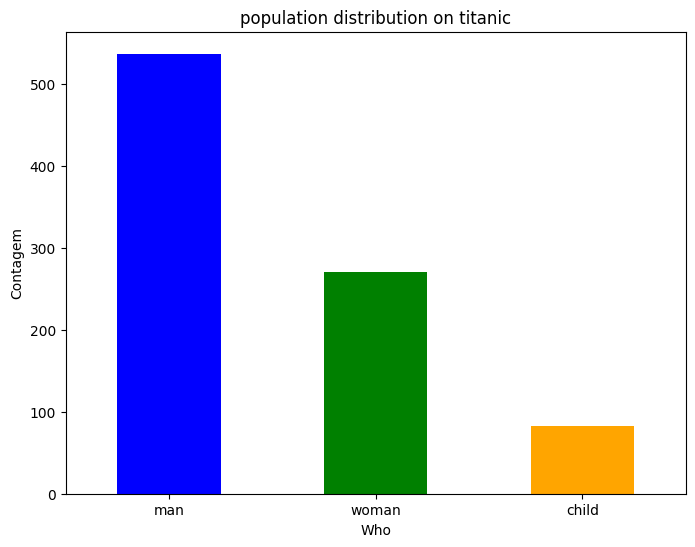

In [176]:
plt.figure(figsize=(8, 6))
titanic['who'].value_counts().plot(kind='bar', color=['blue', 'green', 'orange'])
plt.title('population distribution on titanic')
plt.xlabel('Who')
plt.ylabel('Contagem')
plt.xticks(rotation=0)
plt.show()



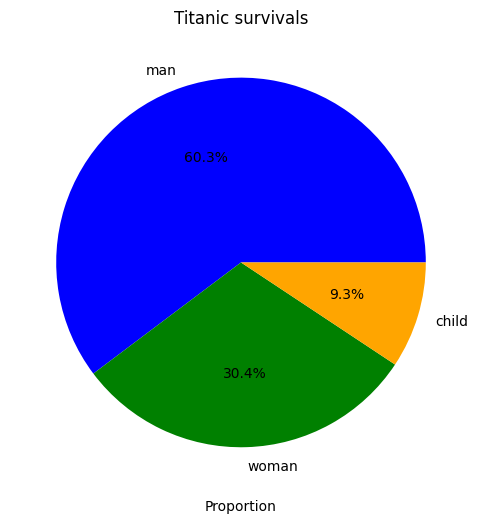

In [177]:
## Pie Chart

plt.figure(figsize=(10,6))

titanic['who'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['blue', 'green', 'orange'])
plt.title('Titanic survivals')
plt.xlabel('Proportion')
plt.ylabel('')
plt.show()

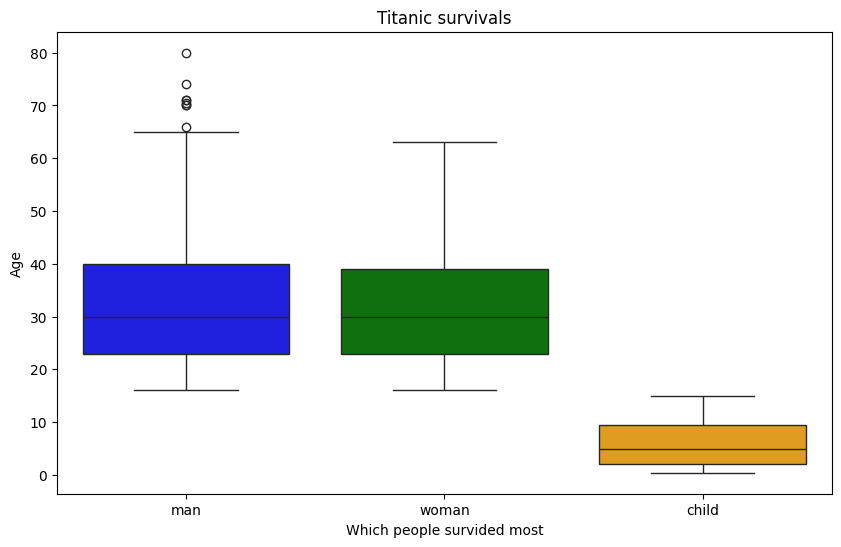

In [178]:
## Box Chart


plt.figure(figsize=(10,6))
sns.boxplot(data=titanic, x="who", y="age", hue="who", legend=False, palette=['blue', 'green', 'orange'])
plt.title('Titanic survivals')
plt.xlabel('Which people survided most')
plt.ylabel('Age')
plt.show()

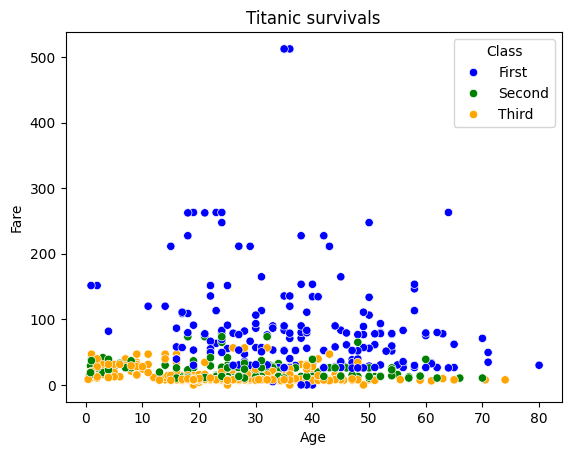

In [179]:
## Dispersion Graphs

sns.scatterplot(data=titanic, x="age", y="fare", hue="class", palette=['blue', 'green', 'orange'])
plt.title('Titanic survivals')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title='Class')
plt.show()

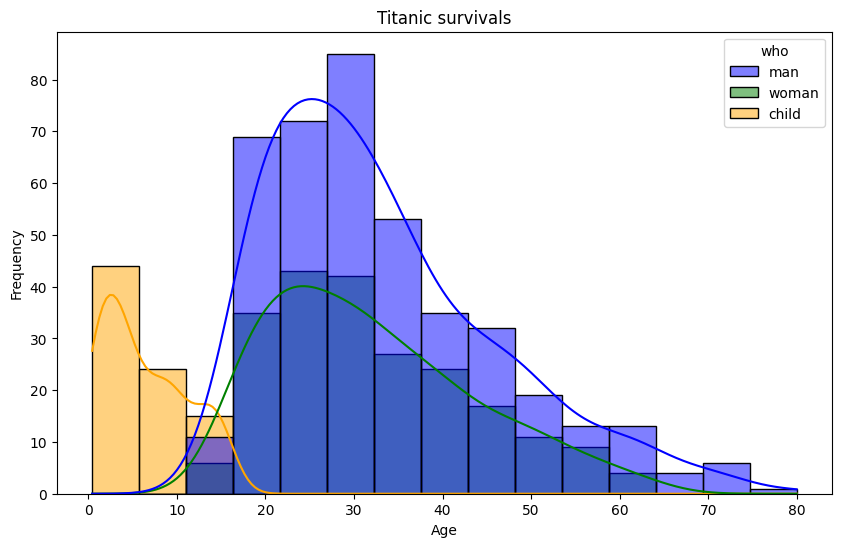

In [180]:
## Histogram
plt.figure(figsize=(10,6))

sns.histplot(data=titanic, x="age", hue="who", kde=True, palette=['blue', 'green', 'orange'], bins=15)
plt.title('Titanic survivals')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

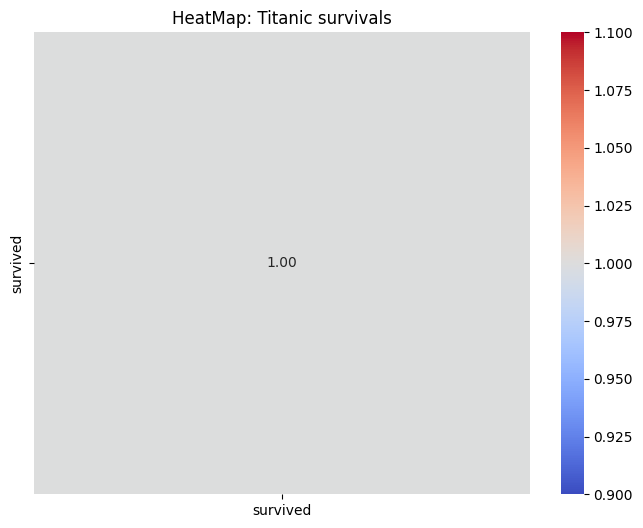

In [181]:
## Heatmap

plt.figure(figsize=(8,6))
sns.heatmap(titanic.iloc[:, :1].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('HeatMap: Titanic survivals')
plt.show()

## **Questão 1 – Probabilidade**

1. Considere um experimento simples de lançamento de um dado justo de seis faces.

   * Calcule a probabilidade de sair um número par.  
   * Calcule a probabilidade de sair um número maior que 4.  
   * Calcule a probabilidade de sair um número par e maior que 4.  
   * Calcule a probabilidade de sair um número par ou maior que 4.

2. Simule o lançamento de um dado 10.000 vezes e apresente:
   * A frequência relativa de cada número.  
   * Um gráfico de barras com as frequências observadas.  
   * Compare os resultados simulados com a probabilidade teórica.

---

## **Questão 2 – Distribuições Discretas e Contínuas**

1. Gere uma amostra aleatória de 1000 observações de uma **Distribuição Binomial** com parâmetros n = 10 e p = 0.5.

   * Calcule a média e o desvio padrão teóricos e amostrais.  
   * Construa o histograma da distribuição.  
   * Compare com a curva da distribuição teórica.

2. Gere uma amostra de 1000 observações de uma **Distribuição Normal** com média 50 e desvio padrão 10.

   * Calcule a média e desvio padrão amostral.  
   * Construa o histograma e sobreponha a curva da distribuição normal teórica.  
   * Calcule a probabilidade de observar valores entre 40 e 60.  

3. Interprete os resultados obtidos e discuta as diferenças entre distribuições discretas e contínuas.

---

## **Questão 3 – Distribuições Amostrais e Estimação**

1. Gere 100 amostras aleatórias de tamanho n = 30 a partir de uma distribuição normal com média 100 e desvio padrão 15.  

   * Calcule a média de cada amostra e armazene os valores.  
   * Construa o histograma das médias amostrais.  
   * Compare com a distribuição original e interprete os resultados à luz do **Teorema Central do Limite**.

2. Estime o intervalo de confiança de 95% para a média populacional com base nas amostras.  

   * Interprete o resultado do intervalo de confiança.  
   * Explique o que ele representa no contexto da inferência estatística.

---

## **Questão 4 – Análise Descritiva**:

* Calcule as seguintes métricas para a variável Age (idade):
  * Média, mediana, moda.
  * Valor mínimo e máximo.
  * Verifique se existem valores nulos.

* Construa os seguintes gráficos:

  * Histograma da idade dos passageiros.
  * Boxplot para a idade em relação à variável Survived (sobrevivência).
  * Gráfico de barras para a frequência de passageiros por classe (Pclass).
  * Gráfico de pizza mostrando a proporção de sobreviventes e não sobreviventes.

Interprete os gráficos e as métricas: que conclusões podem ser tiradas?

---

## **Questão 5 – Teste de Aderência e Teste de Hipótese**

1. **Teste de Aderência**:

* Aplique os testes de aderência (Kolmogorov-Smirnov, Shapiro-Wilk e D’Agostino-Pearson) na variável Fare (tarifa paga).

* Os dados seguem uma distribuição normal? Justifique sua resposta com base nos p-valores.


2. **Teste de Hipótese**:

* Teste a hipótese de que a sobrevivência é independente da classe do passageiro (Pclass).

* Use o **teste qui-quadrado** (Lembre-se de verificar se ele pode realmente ser utilizado) e interprete os resultados.

* Qual é a conclusão sobre a independência entre essas variáveis?

## **Questão 1 – Probabilidade**

1. Considere um experimento simples de lançamento de um dado justo de seis faces.



   * Calcule a probabilidade de sair um número par.  

In [182]:
N = 10000

dado = np.random.randint(1, 7, size=N)
prob_6 = np.mean(dado == 6)
prob_par = np.mean(dado % 2 == 0)
print(prob_par)

0.5021


* Calcule a probabilidade de sair um número maior que 4

In [183]:
prob_maior_4 = np.mean(dado > 4)
print(prob_maior_4)

0.3346


* Calcule a probabilidade de sair um número par e maior que 4.

In [184]:
prob_par_e_maior_4 = np.mean((dado % 2 == 0) & (dado > 4))
print(prob_par_e_maior_4)

0.1657



* Calcule a probabilidade de sair um número par ou maior que 4.



In [185]:
prob_par_ou_maior_4 = np.mean((dado % 2 == 0) | (dado > 4))
print(prob_par_ou_maior_4)

0.671


2. Simule o lançamento de um dado 10.000 vezes e apresente:
   * A frequência relativa de cada número.

In [186]:
np.random.seed(42)
probabilidade_teorica = 1/6 * 100

faces, frequencias_absolutas = np.unique(dado, return_counts=True)
print(faces)
print(frequencias_absolutas)
print(len(dado))
freq_relativas = frequencias_absolutas / len(dado) * 100
print(freq_relativas)

for face, freq in zip(faces, freq_relativas):
    print(f"Face {face}: {freq:.4f} ({freq:.2f}%)")

[1 2 3 4 5 6]
[1665 1692 1625 1672 1689 1657]
10000
[16.65 16.92 16.25 16.72 16.89 16.57]
Face 1: 16.6500 (16.65%)
Face 2: 16.9200 (16.92%)
Face 3: 16.2500 (16.25%)
Face 4: 16.7200 (16.72%)
Face 5: 16.8900 (16.89%)
Face 6: 16.5700 (16.57%)


* Um gráfico de barras com as frequências observadas.



In [187]:
def gera_frequencia(n):
  dado = np.random.randint(1, 7, size=n)
  faces, frequencias_absolutas = np.unique(dado, return_counts=True)
  freq_relativas = frequencias_absolutas / len(dado) * 100

  return faces, freq_relativas

## plota o gráfico
def plot_bar(faces, frequencias_absolutas):
  probabilidade_teorica = 1/6 * 100
  plt.figure(figsize=(8, 6))

  barras = plt.bar(faces, freq_relativas, label='Frequência Observada')

  for barra in barras:
      altura = barra.get_height()
      plt.text(barra.get_x() + barra.get_width()/2.0, altura + 0.3, f'{altura:.2f}%', ha='center', va='bottom', fontsize=10)

  plt.xlabel('Face do Dado')
  plt.ylabel('Frequência Relativa')
  plt.title('Frequência Relativa de Cada Face do Dado')
  plt.axhline(y=probabilidade_teorica, color='tomato', linestyle='--', linewidth=2, label=f'Probabilidade Teórica: {probabilidade_teorica:.2f}')
  plt.ylim(0, 30)
  plt.legend(loc='upper right')

  plt.show()

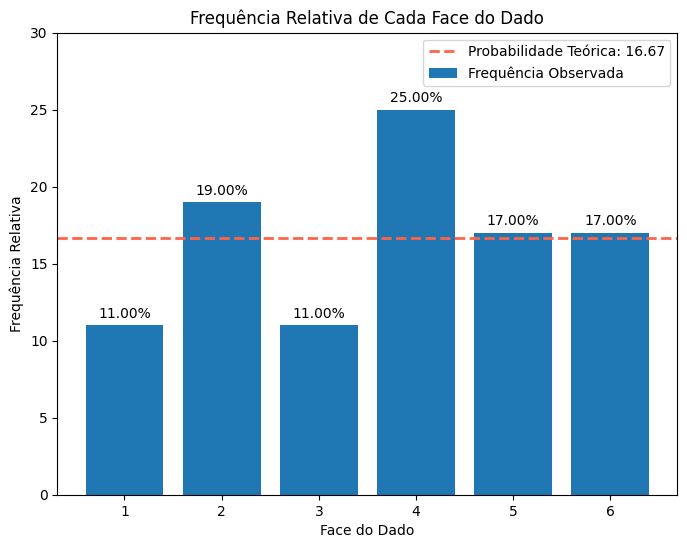

In [188]:
size = 100

faces, freq_relativas = gera_frequencia(size)

plot_bar(faces, frequencias_absolutas)

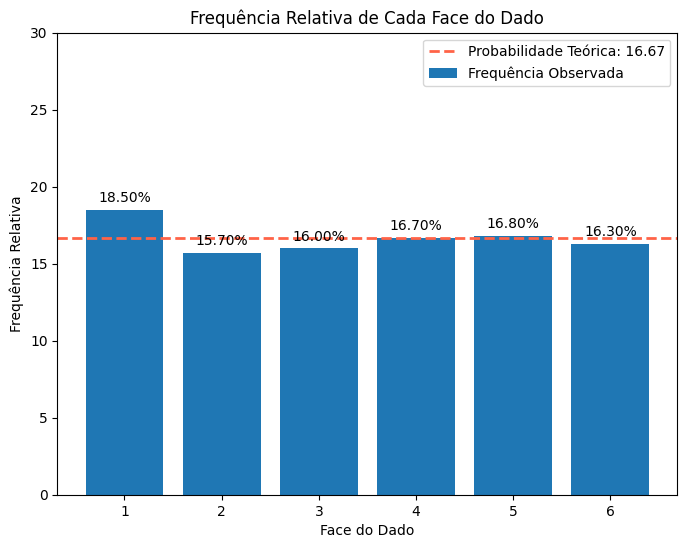

In [189]:
size = 1000

faces, freq_relativas = gera_frequencia(size)

plot_bar(faces, frequencias_absolutas)

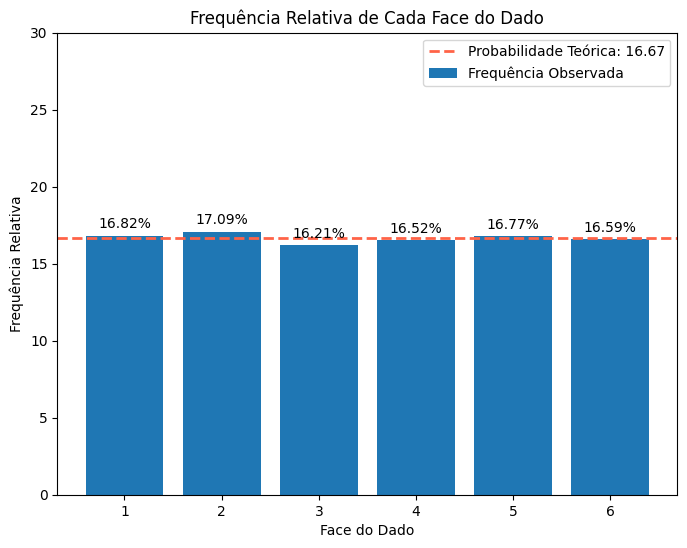

In [190]:
size = 10000

faces, freq_relativas = gera_frequencia(size)

plot_bar(faces, frequencias_absolutas)

* Compare os resultados simulados com a probabilidade teórica.

### Análise
Como podemos ver acima, para valores pequenos(n=100), a frequência relativa tende a ser bem diference do que a teórica, e cada vez que n vai aumentando a sua grandez, a frequência absoluta vai se aproximando cada vez mais da téorica. Isso está de acordo com a Lei dos Grandes Números, à medida que aumentamos a quantidade de experimentos, a frequência observada na prática tende a convergir exatamente para a probabilidade teórica. O gráfico e os dados gerados comprovam esse comportamento, mostrando desvios muito pequenos entre o que simulamos e o modelo matemático teórico.